# SHFLI: pulsed measurement with the Timeline Module

This notebook plays a sequence of pulses on the SHFLI with the **Timeline Module** and records each pulse
in two ways at the same time:

* **Demodulator** (`demod0`, 50 MSa/s): R and θ, acquired with the DAQ module.
* **Scope** (`scope0`, 2 GSa/s): the raw input signal, acquired with the Scope module.

Each step of the sequence first sets parameters (oscillator frequency, phase, output gain), then plays one
pulse while both measurements run. Here two steps are used: 100 kHz with a 10 µs pulse, then 10 kHz with a 16 µs pulse.

**Requirements**
* LabOne **26.11** or newer (data server and Python API). The elements `setParameter` and
  `resetOscillatorPhase` used below are not available in older versions.
* Python packages: `zhinst-toolkit`, `numpy`, `matplotlib`.

**Notebook outline**
1. Connect to the instrument
2. Configure inputs, outputs and the demodulator
3. Set up the Timeline Module and the measurement timing
4. Build and upload the pulse sequence
5. Arm the scope
6. Run the sequence and acquire the demodulator data
7. Plot the demodulator data
8. Read and plot the scope data

In [1]:
# Copyright 2023 Zurich Instruments AG
import time
from timeit import default_timer as timer
import numpy as np
from zhinst.toolkit import Session, CommandTable
import matplotlib.pyplot as plt
import matplotlib as mpl
import json

## 1. Connect to the instrument

Set `shfli_id` to the serial number of your SHFLI (rear panel, e.g. `dev12470`) and `server_host` to the
address of the PC running the LabOne data server (`'localhost'` if it is the same PC).

In [2]:
shfli_id = "dev12470"          # SHFLI serial number, printed on the rear panel
server_host = '10.42.193.0'    # data server address; use 'localhost' if LabOne runs on this PC

# Connect to the data server and to the SHFLI
session = Session(server_host, allow_version_mismatch=True)
shfli = session.connect_device(shfli_id)
print(shfli)

BaseInstrument(SHFLI(AWG,FF,MF,MOD,PID),dev12470)


## 2. Configure inputs, outputs and the demodulator

All indices are 0-based: `sig_ch = 1` is **Signal Output 2 / Signal Input 2** on the front panel.

* **Output:** the RF output is the synthesizer center frequency (3.5 GHz) plus the oscillator frequency.
  The generator starts disabled; the Timeline Module switches the pulses on and off.
* **Input:** AC coupled, used by both the demodulator and the scope.
* **Demodulator 0:** filter bypassed (`bypass(1)`), so the demodulator samples follow the signal without
  low-pass filtering. This is what you want for short pulses.

In [3]:
sig_ch    = 1        # Signal Output / Input 2 (0-based index)
sig_gen   = 7        # generator used on that output
synth_num = 1        # synthesizer for this channel
osc_num   = 1        # oscillator driving the generator
lo_freq   = 3.5e9    # synthesizer center frequency (Hz)
if_freq   = 260e6    # oscillator (IF) frequency (Hz)
demod     = 0        # demodulator used for the measurement

In [4]:
with shfli.set_transaction():          # send all settings in one go
    # Signal output: range, offset, all generators off except the one we use
    shfli.sigouts[sig_ch].range(0)
    shfli.sigouts[sig_ch].offset(0)
    shfli.sigouts[sig_ch].generators["*"].enable(0)
    shfli.sigouts[sig_ch].generators[sig_gen].amplitude(0.01)

    # Carrier: synthesizer center frequency + oscillator offset
    shfli.synthesizers[synth_num].centerfreq(3.5e9)
    shfli.oscs[osc_num].freq(260e6)

    # Generator: which oscillator it uses, harmonic and phase
    shfli.generators[sig_gen].oscselect(osc_num)
    shfli.generators[sig_gen].harmonic(1)
    shfli.generators[sig_gen].phaseshift(0)

    # Keep the generator off (the Timeline plays the pulses), switch the output on
    shfli.sigouts[sig_ch].generators[sig_gen].enable(0)
    shfli.sigouts[sig_ch].on(1)

    # Signal input: range, AC coupling, on
    shfli.sigins[sig_ch].range(0)
    shfli.sigins[sig_ch].ac(1)
    shfli.sigins[sig_ch].on(1)

    # Demodulator: input, oscillator, phase; filter bypassed for pulsed measurements
    shfli.demods[demod].adcselect(1)
    shfli.demods[demod].oscselect(0)
    shfli.demods[demod].phaseshift(0)
    shfli.demods[demod].bypass(1)
    shfli.demods[demod].order(2)
    shfli.demods[demod].timeconstant(30e-6)

## 3. Set up the Timeline Module and the measurement timing

The Timeline Module turns a JSON description of the pulse sequence into instrument instructions.
`modulation.type` selects how each signal output is modulated while the Timeline plays.

The measurement window is set by `meas_duration_nominal` (here 20 µs). At the demodulator rate of 50 MSa/s
this gives `burst_length` samples per measurement; the DAQ module uses this number below.

In [5]:
tlm = session.modules.timeline
tlm.device(shfli_id)
tlm.sigouts[0].modulation.type(7)      # modulation mode of Signal Output 1 during the Timeline
tlm.sigouts[1].modulation.type(6)      # modulation mode of Signal Output 2 during the Timeline

In [6]:
data_rate = 50e6                    # demodulator sample rate during the measurement (Sa/s)
meas_duration_nominal = 20.0e-6     # requested measurement window (s)
burst_length = int(np.ceil(data_rate * meas_duration_nominal))   # samples per measurement
meas_duration = burst_length / data_rate                          # exact window, a whole number of samples

print(f"Data rate: {data_rate} Sa/s")
print(f"Burst length: {burst_length}")
print(f"Acquisition length {meas_duration} s")

Data rate: 50000000.0 Sa/s
Burt length: 1001
Acquisition length 2.002e-05 s


## 4. Build and upload the pulse sequence

The sequence is a JSON object: a `block` containing a list (`sequence`) of elements that are played one after
the other. Small helper functions build the elements so that each step stays readable:

* `set_parameter(quantity, target, value)` changes a setting at that point in the sequence,
  e.g. the frequency of oscillator 0.
* `measurement(rate)` starts a measurement of length `meas_duration` at the given rate.
* `step(frequency, pulse_duration)` returns one complete step: set frequency, phase and gain, reset the
  oscillator phases, then one **section** in which the pulse on `sigout1` and the `scope0` and `demod0`
  measurements start together.

`*step(...)` unpacks the list returned by `step()` into the sequence, so the sequence stays a flat list of
elements. To add a step, add another `*step(...)` line.

The sequence is checked when it is uploaded with `tlm.sequence.sourcestring(...)`. If an element is not
valid, this raises an error listing the problem.

In [7]:
def set_parameter(quantity, target, value):
    """Change one setting at this point in the sequence."""
    return {"type": "setParameter", "quantity": quantity, "target": target, "value": value}

def measurement(rate):
    """A measurement of length meas_duration at the given sample rate (Sa/s)."""
    return {"type": "measurement", "rate": rate, "duration": meas_duration}

def step(frequency, pulse_duration):
    """One step: set parameters, then one section with the pulse and both measurements."""
    return [
        set_parameter("frequency", "osc0", frequency),         # oscillator 0 frequency (Hz)
        set_parameter("phase", "sineGen0", 90),                # sine generator 0 phase (deg)
        set_parameter("gain", "sigout1/generator7", 0.5),      # output gain of generator 7 on output 2
        {"type": "resetOscillatorPhase", "oscillators": [0, 2]},
        {
            "type": "section",
            "minDuration": 10e-6,                              # section lasts at least 10 µs
            "signals": {
                "sigout1": [                                   # pulse on Signal Output 2
                    {"type": "pulse", "duration": pulse_duration, "waveform": "ones", "amplitude": 1}
                ],
                "scope0": [measurement(2e9)],                  # scope at 2 GSa/s
                "demod0": [measurement(50e6)],                 # demodulator at 50 MSa/s
            },
        },
    ]


config = {
    "meta": {"schemaVersion": "1.0.0"},
    "block": {
        "type": "block",
        "sequence": [
            *step(frequency=100e3, pulse_duration=10e-6),
            *step(frequency=10e3, pulse_duration=16e-6),
        ],
    },
}

# Upload the sequence (it is validated here) and print it for reference
json_string = json.dumps(config)
tlm.sequence.sourcestring(json_string)
print(json.dumps(config, indent=2))

{
  "meta": {
    "schemaVersion": "1.0.0"
  },
  "block": {
    "type": "block",
    "sequence": [
      {
        "type": "setParameter",
        "quantity": "frequency",
        "target": "osc0",
        "value": 100000.0
      },
      {
        "type": "setParameter",
        "quantity": "phase",
        "target": "sineGen0",
        "value": 90
      },
      {
        "type": "setParameter",
        "quantity": "gain",
        "target": "sigout1/generator7",
        "value": 0.5
      },
      {
        "type": "resetOscillatorPhase",
        "oscillators": [
          0,
          2
        ]
      },
      {
        "type": "section",
        "minDuration": 1e-05,
        "signals": {
          "sigout1": [
            {
              "type": "pulse",
              "duration": 1e-05,
              "waveform": "ones",
              "amplitude": 1
            }
          ],
          "scope0": [
            {
              "type": "measurement",
              "rate": 2000000000.

## 5. Arm the scope

The scope records Signal Input 2 on both scope channels. It is triggered by the Timeline measurement
(`trigger.channel(17)`), so each `scope0` measurement in the sequence produces one scope record.
Run this cell before the next one: the scope must be waiting when the Timeline starts.

In [8]:
scope = session.modules.scope

# Subscribe to the waveforms of scope channels 0 and 1
scope_nodes = [shfli.scopes[0].channels[ch].wave for ch in (0, 1)]
for node in scope_nodes:
    scope.subscribe(node)

# Both scope channels record Signal Input 2
input_ch = [0, 1]
for input in input_ch:
    shfli.scopes[0].channels[input].inputselect("sigin1")
for input in input_ch:
    shfli.scopes[0].channels[input].enable(1)

scope.mode(1)                              # time-domain data
shfli.scopes[0].single(1)                  # single shot
shfli.scopes[0].enable(1)                  # arm the scope
shfli.scopes[0].trigger.channel(17)        # trigger from the Timeline measurement
shfli.scopes[0].trigger.enable(1)

scope.save.directory('/home/app/Zurich Instruments/LabOne/WebServer')

## 6. Run the sequence and acquire the demodulator data

The DAQ module is set to **burst trigger** mode: it starts recording whenever the Timeline starts a
`demod0` measurement and takes `burst_length` samples (R and θ). The order matters:

1. Arm the DAQ module and the scope module (`execute()`).
2. Start the Timeline (`tlm.execute()`).
3. Wait until both the Timeline and the DAQ module are finished (timeout 10 s).

In [9]:
# DAQ module: one burst of burst_length samples per Timeline demod measurement
triggernode_path = f"/{shfli_id}/demods/0/sample.TrigIndex"
daq_module = session.modules.daq
daq_module.device(shfli_id)

daq_module.type("burst_trigger")             # trigger on the demodulator trigger index (Timeline measurements)
daq_module.triggernode(triggernode_path)
daq_module.holdoff.time(0)
daq_module.grid.mode(4)                      # 4 = exact: no resampling
daq_module.grid.cols(burst_length)           # samples per burst
daq_module.grid.repetitions(1)

# Signals to record: R and θ of the demodulator
signal_nodes = [
    shfli.demods[demod].sample.r,
    shfli.demods[demod].sample.theta,
]
signal_paths = [node.node_info.path for node in signal_nodes]   # e.g. "/dev12470/demods/0/sample.r"
for node in signal_nodes:
    daq_module.subscribe(node)
daq_module.execute()

# Arm the scope module, then start the Timeline
scope.execute()
time.sleep(1)
time_meas_start = time.time()
print("Starting Timeline execution...")
tlm.execute()

# Wait for the Timeline and the DAQ module to finish
timeout_sec = 10.0
start = time.time()
while not (tlm.finished() and daq_module.finished()):
    if time.time() - start > timeout_sec:
        tlm.finish()
        print("Timeout occurred.")
        break
    time.sleep(0.5)
    print(f"Progress: {daq_module.progress() * 100:.0f}%\r")

print(f"Timeline execution finished with {daq_module.progress() * 100:.0f}% progress.")
daq_module.unsubscribe("*")
data = daq_module.read()   # dict: node path -> list of DAQResult(header, value, time, frequency, shape)
time_meas_end = time.time()
print(f"Finished in {time_meas_end - time_meas_start:0.2f} s")

Starting Timeline execution...
Progress: 100%
Timeline execution finished with 100% progress.
Finished in 0.54 s


## 7. Plot the demodulator data

`data[path]` is a list of results; `[0]` is the first (here the only) one. Its `.value` is a 2D array with
one row per trigger and `burst_length` columns. The sample spacing is in the header (`gridcoldelta`, 20 ns at 50 MSa/s).

(1, 1001) dt = 20 ns


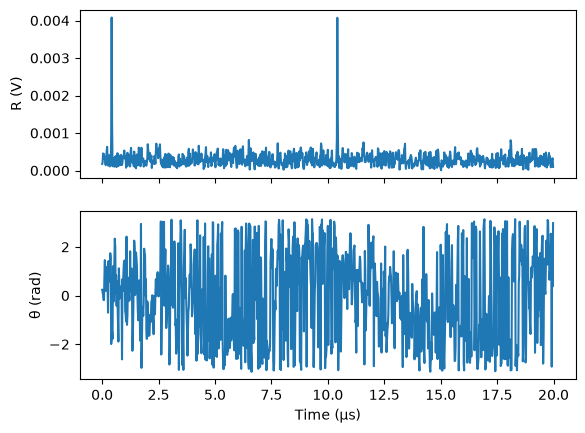

In [10]:
res_r  = data[signal_paths[0]][0]     # sample.r
res_th = data[signal_paths[1]][0]     # sample.theta

r     = res_r.value                   # shape (rows, burst_length)
theta = res_th.value
dt    = res_r.header["gridcoldelta"][0]          # sample spacing (s)
t     = np.arange(r.shape[1]) * dt               # time after the start of the measurement

print(r.shape, f"dt = {dt*1e9:.0f} ns")

fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(t * 1e6, r[0]);      ax[0].set_ylabel("R (V)")
ax[1].plot(t * 1e6, theta[0]);  ax[1].set_ylabel("θ (rad)")
ax[1].set_xlabel("Time (µs)")
plt.show()

## 8. Read and plot the scope data

Run this right after step 6: each `scope.read()` returns the records received so far and empties the module.
`scope_data[path]` is a list of records, one per scope trigger. In each record, `[0]["wave"]` holds the samples
in V and `[0]["dt"]` the sample spacing (0.5 ns at 2 GSa/s).

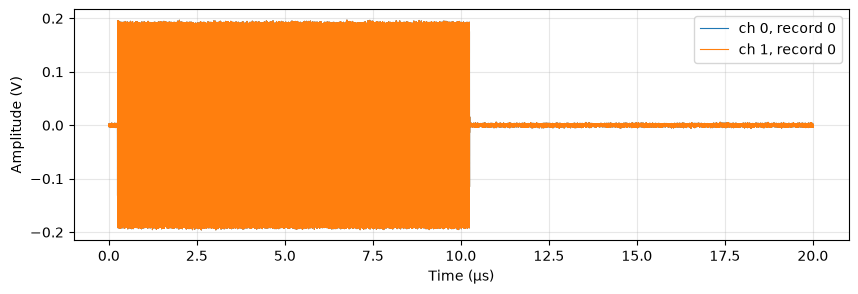

In [11]:
# Wait for the scope record(s), then read them
t0 = time.time()
while scope.records() < 1 and time.time() - t0 < 5:      # wait up to 5 s for the first record
    time.sleep(0.1)
time.sleep(0.2)                                           # let any further records arrive
scope_data = scope.read()
scope.finish(); scope.unsubscribe("*")

fig, ax = plt.subplots(figsize=(10, 3))
for ch, node in enumerate(scope_nodes):
    path = node.node_info.path
    for k, rec in enumerate(scope_data[path] if path in scope_data else []):
        y = rec[0]["wave"][0]                             # samples in V
        t_us = np.arange(len(y)) * rec[0]["dt"] * 1e6     # time axis in µs
        ax.plot(t_us, y, lw=0.8, label=f"ch {ch}, record {k}")
ax.set(xlabel="Time (µs)", ylabel="Amplitude (V)"); ax.grid(alpha=0.3); ax.legend()
plt.show()